In [66]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import torch
import pickle

In [67]:
df = pd.read_csv("sleep_debt_screen_time.csv")

In [68]:
df.head()

,user_id,age,gender,chronotype,occupation,bedtime_hour,screen_time_before_bed_min,primary_app_category,screen_brightness_pct,blue_light_filter_on,...,room_temperature_f,ambient_noise_db,sleep_onset_latency_min,total_sleep_hours,rem_sleep_pct,deep_sleep_pct,awakenings_count,sleep_efficiency_pct,next_day_fatigue_score,sleep_debt_category
0,1,32,Female,Intermediate,Student,23.94,102,Social Media,100,False,...,73.5,32.6,60.3,5.67,15.2,13.5,11,63.7,8.85,Moderate
1,2,26,Female,Intermediate,Student,0.06,14,Short-Form Video,87,True,...,66.8,44.3,24.5,7.42,16.9,22.3,1,92.9,2.98,No Debt
2,3,34,Male,Night Owl,Professional,1.48,58,Messaging,76,True,...,68.0,45.6,21.9,6.98,20.2,18.5,2,84.6,3.90,Mild
3,4,43,Female,Intermediate,Professional,22.42,48,Social Media,56,False,...,72.3,42.3,34.5,7.67,14.4,17.3,6,79.9,4.81,No Debt
4,5,25,Male,Early Bird,Professional,22.43,29,Streaming,96,True,...,80.1,10.0,37.4,6.31,16.6,16.1,0,89.3,3.88,Mild


In [69]:
df = df.drop(df[df["sleep_debt_category"] == "Severe"].index)

In [70]:
df["sleep_debt_category"] = df["sleep_debt_category"].map({
    "No Debt": 0,
    "Mild": 1,
    "Moderate": 2
})

In [71]:
df

,user_id,age,gender,chronotype,occupation,bedtime_hour,screen_time_before_bed_min,primary_app_category,screen_brightness_pct,blue_light_filter_on,...,room_temperature_f,ambient_noise_db,sleep_onset_latency_min,total_sleep_hours,rem_sleep_pct,deep_sleep_pct,awakenings_count,sleep_efficiency_pct,next_day_fatigue_score,sleep_debt_category
0,1,32,Female,Intermediate,Student,23.94,102,Social Media,100,False,...,73.5,32.6,60.3,5.67,15.2,13.5,11,63.7,8.85,2
1,2,26,Female,Intermediate,Student,0.06,14,Short-Form Video,87,True,...,66.8,44.3,24.5,7.42,16.9,22.3,1,92.9,2.98,0
2,3,34,Male,Night Owl,Professional,1.48,58,Messaging,76,True,...,68.0,45.6,21.9,6.98,20.2,18.5,2,84.6,3.90,1
3,4,43,Female,Intermediate,Professional,22.42,48,Social Media,56,False,...,72.3,42.3,34.5,7.67,14.4,17.3,6,79.9,4.81,0
4,5,25,Male,Early Bird,Professional,22.43,29,Streaming,96,True,...,80.1,10.0,37.4,6.31,16.6,16.1,0,89.3,3.88,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8495,8496,35,Male,Early Bird,Retired,22.16,76,Gaming,83,False,...,68.0,16.1,33.8,6.57,15.5,14.0,3,81.7,4.96,1
8496,8497,33,Female,Intermediate,Freelancer,23.14,102,E-Reading,55,False,...,71.1,41.0,14.8,7.00,20.3,20.4,2,81.9,4.06,1
8497,8498,40,Female,Intermediate,Student,0.76,52,Streaming,87,True,...,71.9,41.2,16.8,6.51,17.3,17.2,0,77.8,4.27,1
8498,8499,16,Male,Night Owl,Student,1.60,53,Gaming,72,True,...,67.2,23.5,25.6,7.47,12.4,18.7,3,87.3,4.49,1


In [72]:
df.shape

(8475, 23)

In [73]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8475 entries, 0 to 8499
Data columns (total 23 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   user_id                     8475 non-null   int64  
 1   age                         8475 non-null   int64  
 2   gender                      8475 non-null   object 
 3   chronotype                  8475 non-null   object 
 4   occupation                  8475 non-null   object 
 5   bedtime_hour                8475 non-null   float64
 6   screen_time_before_bed_min  8475 non-null   int64  
 7   primary_app_category        8475 non-null   object 
 8   screen_brightness_pct       8475 non-null   int64  
 9   blue_light_filter_on        8475 non-null   bool   
 10  caffeine_intake_mg          8475 non-null   int64  
 11  caffeine_last_hour          8475 non-null   float64
 12  physical_activity_min       8475 non-null   int64  
 13  room_temperature_f          8475 non-n

In [74]:
df["sleep_debt_category"].unique()

array([2, 0, 1])

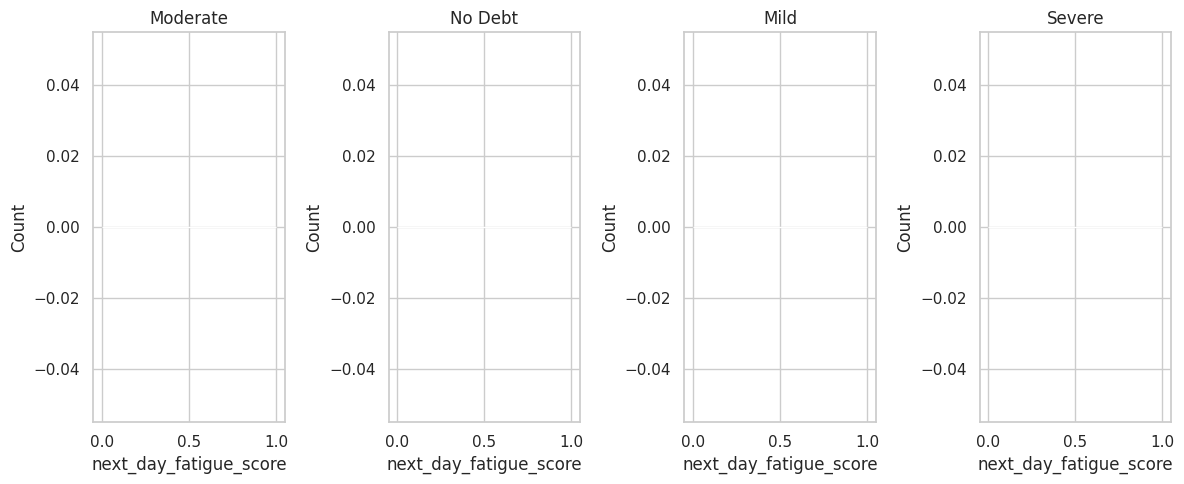

In [75]:
plt.figure(figsize=(12,5))
sns.set_theme(style="whitegrid")
plt.subplot(1,4,1)
sns.histplot(data=df[df["sleep_debt_category"] == "Moderate"], x="next_day_fatigue_score", kde=True, color="green")
plt.title("Moderate")


plt.subplot(1,4,2)
sns.histplot(data=df[df["sleep_debt_category"] == "No Debt"], x="next_day_fatigue_score", kde=True, color="wheat")
plt.title("No Debt")

plt.subplot(1,4,3)
sns.histplot(data=df[df["sleep_debt_category"] == "Mild"], x="next_day_fatigue_score", kde=True, color="skyblue")
plt.title("Mild")

plt.subplot(1,4,4)
sns.histplot(data=df[df["sleep_debt_category"] == "Severe"], x="next_day_fatigue_score", kde=True, color="crimson")
plt.title("Severe")


plt.tight_layout()
plt.show()

In [76]:
# fatigue score ve sleep debt category biribirleri yerine kullanılabileceği için ve sınıflandırma yapacağım için score kolonunu çıkarmayı düşünüyorum.

In [77]:
cat_features = [col for col in df.columns if df[col].dtype == "O"]
num_features = [col for col in df.columns if df[col].dtype != "O"]

In [78]:
cat_features

['gender', 'chronotype', 'occupation', 'primary_app_category']

In [79]:
num_features

['user_id',
 'age',
 'bedtime_hour',
 'screen_time_before_bed_min',
 'screen_brightness_pct',
 'blue_light_filter_on',
 'caffeine_intake_mg',
 'caffeine_last_hour',
 'physical_activity_min',
 'room_temperature_f',
 'ambient_noise_db',
 'sleep_onset_latency_min',
 'total_sleep_hours',
 'rem_sleep_pct',
 'deep_sleep_pct',
 'awakenings_count',
 'sleep_efficiency_pct',
 'next_day_fatigue_score',
 'sleep_debt_category']

In [80]:
num_features

['user_id',
 'age',
 'bedtime_hour',
 'screen_time_before_bed_min',
 'screen_brightness_pct',
 'blue_light_filter_on',
 'caffeine_intake_mg',
 'caffeine_last_hour',
 'physical_activity_min',
 'room_temperature_f',
 'ambient_noise_db',
 'sleep_onset_latency_min',
 'total_sleep_hours',
 'rem_sleep_pct',
 'deep_sleep_pct',
 'awakenings_count',
 'sleep_efficiency_pct',
 'next_day_fatigue_score',
 'sleep_debt_category']

In [81]:
df["blue_light_filter_on"] = df["blue_light_filter_on"].astype(int)

In [82]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8475 entries, 0 to 8499
Data columns (total 23 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   user_id                     8475 non-null   int64  
 1   age                         8475 non-null   int64  
 2   gender                      8475 non-null   object 
 3   chronotype                  8475 non-null   object 
 4   occupation                  8475 non-null   object 
 5   bedtime_hour                8475 non-null   float64
 6   screen_time_before_bed_min  8475 non-null   int64  
 7   primary_app_category        8475 non-null   object 
 8   screen_brightness_pct       8475 non-null   int64  
 9   blue_light_filter_on        8475 non-null   int64  
 10  caffeine_intake_mg          8475 non-null   int64  
 11  caffeine_last_hour          8475 non-null   float64
 12  physical_activity_min       8475 non-null   int64  
 13  room_temperature_f          8475 non-n

In [83]:
for col in cat_features:
  print(df[col].value_counts(normalize=True))

gender
Female        0.482714
Male          0.476578
Non-Binary    0.040708
Name: proportion, dtype: float64
chronotype
Intermediate    0.408378
Night Owl       0.347729
Early Bird      0.243894
Name: proportion, dtype: float64
occupation
Professional    0.350560
Student         0.304543
Freelancer      0.147611
Retired         0.099705
Unemployed      0.097581
Name: proportion, dtype: float64
primary_app_category
Short-Form Video    0.290147
Social Media        0.215693
Streaming           0.140531
Gaming              0.103599
Messaging           0.088614
E-Reading           0.083776
News                0.077640
Name: proportion, dtype: float64


In [84]:
num_features

['user_id',
 'age',
 'bedtime_hour',
 'screen_time_before_bed_min',
 'screen_brightness_pct',
 'blue_light_filter_on',
 'caffeine_intake_mg',
 'caffeine_last_hour',
 'physical_activity_min',
 'room_temperature_f',
 'ambient_noise_db',
 'sleep_onset_latency_min',
 'total_sleep_hours',
 'rem_sleep_pct',
 'deep_sleep_pct',
 'awakenings_count',
 'sleep_efficiency_pct',
 'next_day_fatigue_score',
 'sleep_debt_category']

In [85]:
num_features.remove("sleep_debt_category")

In [86]:
num_features.pop(0)

'user_id'

<Axes: >

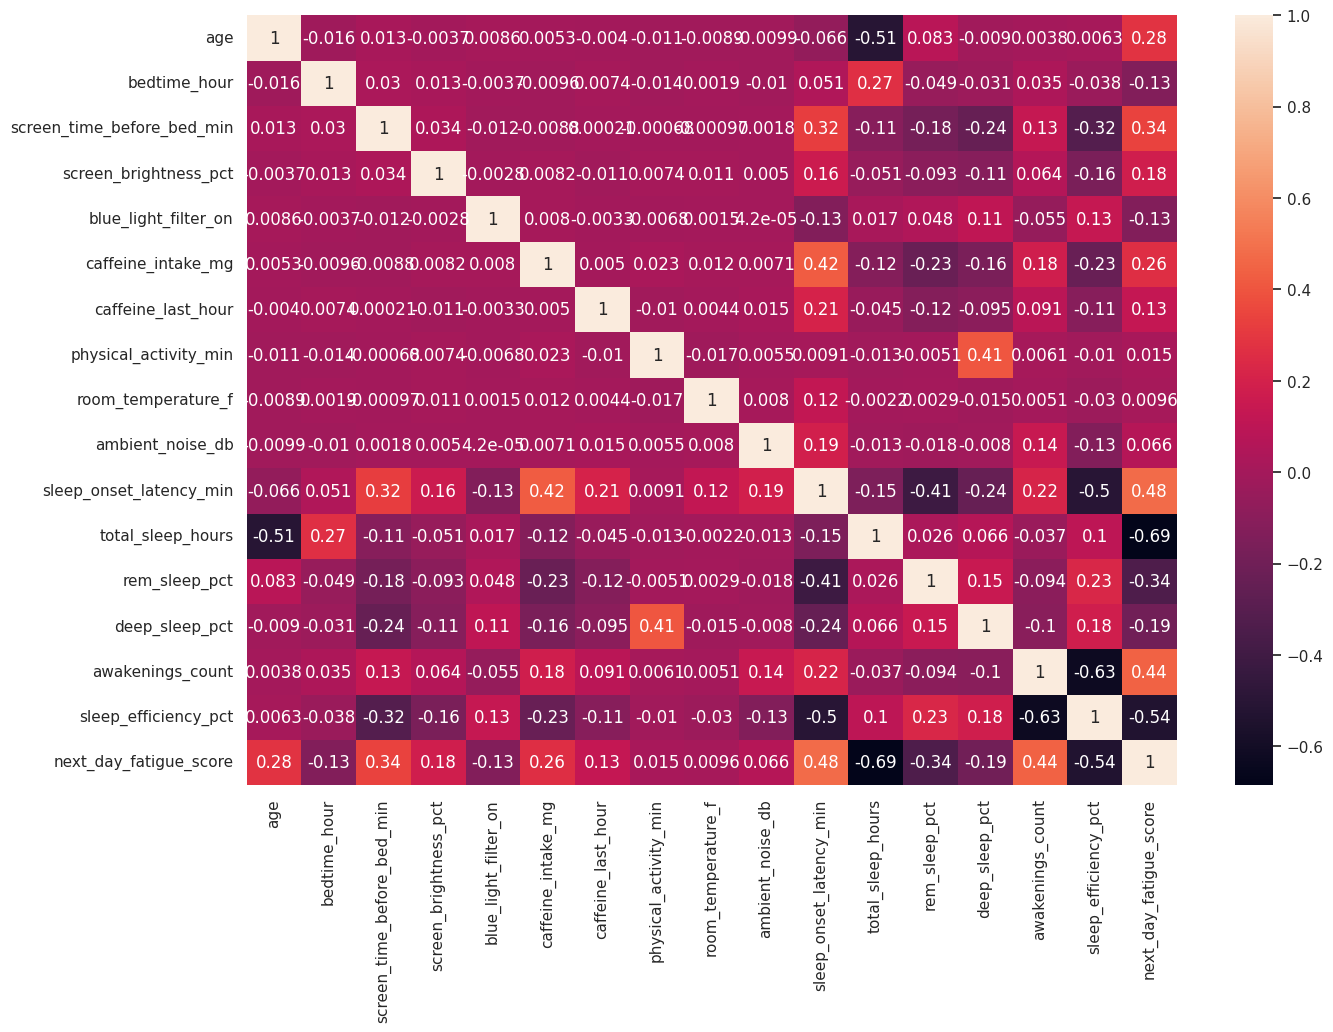

In [87]:
plt.figure(figsize=(15,10))
sns.heatmap(df[num_features].corr(), annot=True)


In [88]:
cat_features

['gender', 'chronotype', 'occupation', 'primary_app_category']

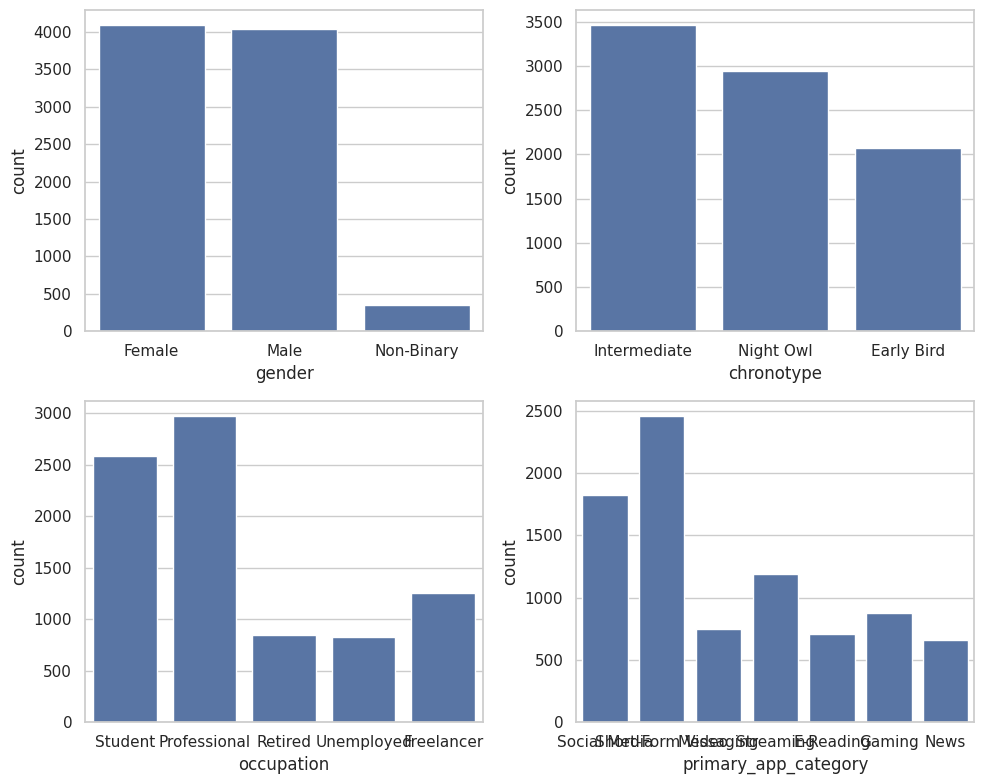

In [24]:

plt.figure(figsize=(10,8))
for index, col in enumerate(cat_features, start=1):
  plt.subplot(2,2, index)
  sns.countplot(data=df, x=col)
  plt.tight_layout()

plt.show()

In [25]:
from scipy.stats import chi2_contingency

ct0 = pd.crosstab(
    df["gender"],
    df["sleep_debt_category"]
)

In [26]:
ts, p_value, ddof, exp_freq = chi2_contingency(ct0)

In [27]:
p_value

np.float64(0.3804849385678823)

In [28]:
ct0 = pd.crosstab(
    df["chronotype"],
    df["sleep_debt_category"]
)

ts, p_value, ddof, exp_freq = chi2_contingency(ct0)

p_value

np.float64(2.21532283822579e-166)

In [29]:
ct0 = pd.crosstab(
    df["occupation"],
    df["sleep_debt_category"]
)

ts, p_value, ddof, exp_freq = chi2_contingency(ct0)

p_value

np.float64(0.1748001982189082)

In [30]:
ct0 = pd.crosstab(
    df["primary_app_category"],
    df["sleep_debt_category"]
)

ts, p_value, ddof, exp_freq = chi2_contingency(ct0)

p_value

np.float64(7.19804930002588e-06)

In [31]:
df.describe()

,user_id,age,bedtime_hour,screen_time_before_bed_min,screen_brightness_pct,blue_light_filter_on,caffeine_intake_mg,caffeine_last_hour,physical_activity_min,room_temperature_f,ambient_noise_db,sleep_onset_latency_min,total_sleep_hours,rem_sleep_pct,deep_sleep_pct,awakenings_count,sleep_efficiency_pct,next_day_fatigue_score,sleep_debt_category
count,8475.000000,8475.000000,8475.000000,8475.000000,8475.000000,8475.000000,8475.000000,8475.000000,8475.000000,8475.000000,8475.000000,8475.000000,8475.000000,8475.000000,8475.000000,8475.000000,8475.000000,8475.000000,8475.000000
mean,4250.381711,28.107375,13.917083,53.716460,68.772743,0.346195,79.521416,15.901971,29.745015,70.082372,34.959139,31.374619,6.785233,16.928330,17.542808,2.327906,81.997546,4.545042,1.075516
std,2455.138278,9.005756,10.831922,35.313628,18.926464,0.475784,78.175002,3.844319,29.988083,3.963132,10.011035,8.702522,0.859357,2.427143,2.378477,1.618710,4.577126,0.950079,0.689931
min,1.000000,16.000000,0.000000,5.000000,5.000000,0.000000,0.000000,6.000000,0.000000,58.000000,10.000000,6.000000,4.120000,7.600000,9.100000,0.000000,59.600000,1.070000,0.000000
25%,2123.500000,21.000000,1.090000,29.000000,56.000000,0.000000,22.000000,13.200000,8.000000,67.400000,28.200000,25.500000,6.180000,15.300000,15.900000,1.000000,79.100000,3.890000,1.000000
50%,4246.000000,27.000000,22.210000,45.000000,69.000000,0.000000,55.000000,16.000000,20.000000,70.100000,35.000000,30.700000,6.780000,16.900000,17.500000,2.000000,82.200000,4.520000,1.000000
75%,6379.500000,34.000000,23.150000,68.000000,83.000000,1.000000,113.000000,18.700000,42.000000,72.700000,41.500000,36.650000,7.370000,18.600000,19.100000,3.000000,85.100000,5.180000,2.000000
max,8500.000000,65.000000,24.000000,240.000000,100.000000,1.000000,500.000000,23.000000,180.000000,82.000000,70.000000,75.200000,9.690000,27.300000,28.700000,11.000000,95.400000,8.850000,2.000000


In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8475 entries, 0 to 8499
Data columns (total 23 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   user_id                     8475 non-null   int64  
 1   age                         8475 non-null   int64  
 2   gender                      8475 non-null   object 
 3   chronotype                  8475 non-null   object 
 4   occupation                  8475 non-null   object 
 5   bedtime_hour                8475 non-null   float64
 6   screen_time_before_bed_min  8475 non-null   int64  
 7   primary_app_category        8475 non-null   object 
 8   screen_brightness_pct       8475 non-null   int64  
 9   blue_light_filter_on        8475 non-null   int64  
 10  caffeine_intake_mg          8475 non-null   int64  
 11  caffeine_last_hour          8475 non-null   float64
 12  physical_activity_min       8475 non-null   int64  
 13  room_temperature_f          8475 non-n

In [33]:
df = df.drop("user_id", axis=1)

In [34]:
from sklearn.model_selection import train_test_split

X = df.drop("sleep_debt_category", axis=1)
y = df["sleep_debt_category"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

In [35]:
X_test

,age,gender,chronotype,occupation,bedtime_hour,screen_time_before_bed_min,primary_app_category,screen_brightness_pct,blue_light_filter_on,caffeine_intake_mg,...,physical_activity_min,room_temperature_f,ambient_noise_db,sleep_onset_latency_min,total_sleep_hours,rem_sleep_pct,deep_sleep_pct,awakenings_count,sleep_efficiency_pct,next_day_fatigue_score
7026,31,Female,Night Owl,Professional,1.38,50,Messaging,100,0,32,...,26,63.5,31.7,30.1,5.38,18.6,18.4,3,75.6,5.44
4632,31,Female,Intermediate,Professional,23.55,16,News,48,1,8,...,71,66.5,24.5,18.3,6.85,22.8,19.7,4,84.5,3.57
2213,23,Female,Early Bird,Professional,21.80,18,Short-Form Video,59,1,57,...,36,68.6,49.6,41.5,8.23,14.9,22.3,3,82.9,2.84
7378,33,Female,Intermediate,Retired,23.80,36,E-Reading,57,1,4,...,10,73.8,44.7,23.7,7.32,16.4,15.6,0,86.6,2.44
5669,41,Female,Intermediate,Unemployed,22.41,34,Social Media,45,0,33,...,2,69.2,41.6,19.5,7.57,18.7,15.4,0,87.0,3.44
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1132,44,Male,Intermediate,Student,0.07,41,Streaming,78,0,188,...,5,71.5,35.0,33.5,6.36,15.6,18.8,1,85.7,4.56
4249,27,Female,Early Bird,Professional,22.49,31,Social Media,91,0,95,...,171,75.5,31.3,36.9,5.72,20.4,24.4,1,82.0,5.05
518,28,Female,Night Owl,Freelancer,0.92,58,Social Media,55,0,72,...,21,68.0,29.9,33.7,6.22,14.4,14.3,3,80.5,5.47
8277,35,Male,Night Owl,Professional,1.71,50,Social Media,93,0,2,...,1,79.1,10.3,36.0,4.86,15.3,13.6,2,77.7,6.25


In [36]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [37]:
transformer = ColumnTransformer(transformers=
                                [("standardscaler", StandardScaler(), num_features),
                                 ("onehot", OneHotEncoder(drop="first"), cat_features)
                                ], remainder="passthrough")

In [38]:
X_train = transformer.fit_transform(X_train)
X_test = transformer.transform(X_test)

In [39]:
X_train.shape

(6356, 31)

In [40]:
X_test.shape

(2119, 31)

In [41]:
y_train.value_counts()

,count
sleep_debt_category,
1,3294
2,1771
0,1291


In [42]:
y_train = y_train.values

In [43]:
y_test = y_test.values

In [44]:
column_names = transformer.get_feature_names_out()

In [45]:
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

In [46]:
X_train.ndim

2

In [47]:
X_train.shape

torch.Size([6356, 31])

In [48]:
type(X_train)

torch.Tensor

In [49]:
X_train.dtype

torch.float32

In [50]:
from torch import nn
class DigitalInsomniaClassifier(nn.Module):
  def __init__(self):
    super().__init__()

    self.linear_layer_stack = nn.Sequential(
        nn.Linear(31, 15),
        nn.ReLU(),
        nn.Linear(15,15),
        nn.ReLU(),
        nn.Linear(15,3)
    )

  def forward(self, x:torch.tensor) -> torch.tensor:
    return self.linear_layer_stack(x)

In [51]:
model = DigitalInsomniaClassifier()
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model.parameters(), lr=0.01)

In [52]:
!pip install torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 19.4 MB/s eta 0:00:00


In [53]:
from torchmetrics.classification import MulticlassAccuracy

accuracy = MulticlassAccuracy(num_classes=4)

In [54]:
epochs = 200

for epoch in range(epochs):

  model.train()
  y_logits = model(X_train)
  loss = loss_fn(y_logits, y_train)
  y_train_preds = torch.softmax(y_logits, dim=1).argmax(dim=1)
  train_acc = accuracy(y_train_preds, y_train)

  optimizer.zero_grad()
  loss.backward()
  optimizer.step()

  model.eval()
  with torch.inference_mode():
    test_logits = model(X_test)
    test_loss = loss_fn(test_logits, y_test)
    y_test_preds = torch.softmax(test_logits, dim=1).argmax(dim=1)
    test_acc = accuracy(y_test_preds, y_test)

  if epoch % 10 == 0:
    print(f"epoch: {epoch}, Train Loss: {loss}, Train Accuracy: {train_acc}, Test Loss: {test_loss}, Test Accuracy: {test_acc}")

epoch: 0, Train Loss: 1.1326931715011597, Train Accuracy: 0.3119206428527832, Test Loss: 1.0947662591934204, Test Accuracy: 0.35786253213882446
epoch: 10, Train Loss: 0.9391324520111084, Train Accuracy: 0.3333333432674408, Test Loss: 0.9158525466918945, Test Accuracy: 0.33446329832077026
epoch: 20, Train Loss: 0.7231467366218567, Train Accuracy: 0.6479385495185852, Test Loss: 0.6967453360557556, Test Accuracy: 0.6770474314689636
epoch: 30, Train Loss: 0.5081885457038879, Train Accuracy: 0.752911388874054, Test Loss: 0.49176281690597534, Test Accuracy: 0.7682138085365295
epoch: 40, Train Loss: 0.4396005868911743, Train Accuracy: 0.7918431162834167, Test Loss: 0.43364694714546204, Test Accuracy: 0.8014992475509644
epoch: 50, Train Loss: 0.3916498124599457, Train Accuracy: 0.8073101043701172, Test Loss: 0.40481650829315186, Test Accuracy: 0.8139668703079224
epoch: 60, Train Loss: 0.37646234035491943, Train Accuracy: 0.8196715116500854, Test Loss: 0.3957975208759308, Test Accuracy: 0.82219

In [55]:
from torchmetrics.classification import MulticlassConfusionMatrix
confusion_matrix = MulticlassConfusionMatrix(num_classes=3)

In [56]:

train_matrix = confusion_matrix(y_train_preds, y_train)

In [57]:
test_matrix = confusion_matrix(y_test_preds, y_test)

In [58]:
from torchmetrics.utilities.plot import plot_confusion_matrix

(<Figure size 640x480 with 1 Axes>,
 <Axes: xlabel='Predicted class', ylabel='True class'>)

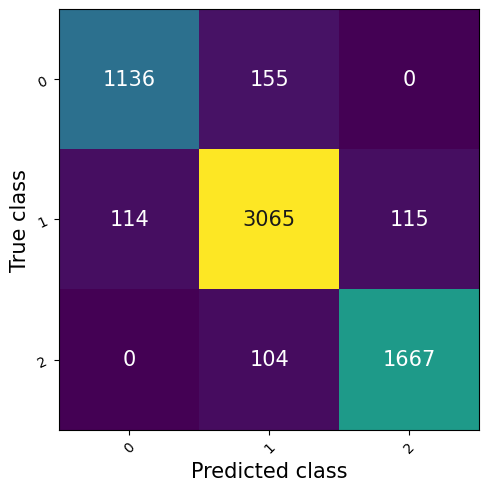

In [59]:
plot_confusion_matrix(train_matrix)

(<Figure size 640x480 with 1 Axes>,
 <Axes: xlabel='Predicted class', ylabel='True class'>)

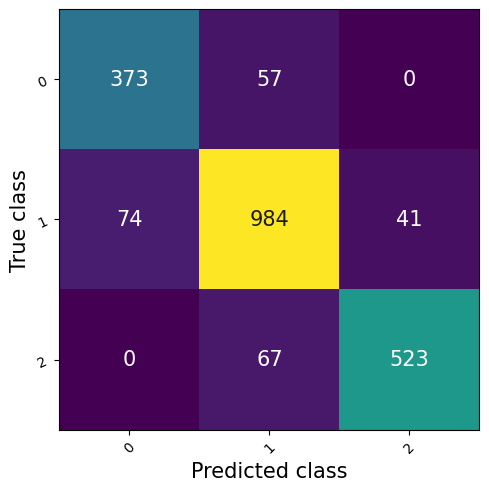

In [60]:
plot_confusion_matrix(test_matrix)

In [61]:
# df["sleep_debt_category"] = df["sleep_debt_category"].map({
#     "No Debt": 0,
#     "Mild": 1,
#     "Moderate": 2
# })

In [62]:
from pathlib import Path

In [63]:
MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)
MODEL_NAME = "digital_insomnia_nn_model.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME

In [64]:
MODEL_SAVE_PATH

PosixPath('models/digital_insomnia_nn_model.pth')

In [65]:
torch.save(obj=model.state_dict(), f=MODEL_SAVE_PATH)

In [89]:
with open(MODEL_PATH / "preprocessor.pkl", "wb") as file:
  pickle.dump(transformer, file)

In [91]:
target_mappings = {
    "No Debt": 0,
    "Mild": 1,
    "Moderate": 2
}

with open(MODEL_PATH / "target_mappings.pkl", "wb") as file:
  pickle.dump(target_mappings, file)